# Summative Lab: DataVine Analytics – Customer Insights & Machine Learning

This starter notebook uses two prepared retail datasets derived from the Online Retail II transactional data:

- `customer_level_online_retail.csv`
- `product_level_online_retail.csv`

You will:
1. Load and inspect both datasets
2. Join them into one analytical dataset
3. Build a **k-NN classification** model to predict customer value segment
4. Build a **product recommendation system**
5. Perform **customer clustering** with K-Means and GMM

**Important:** Keep your code concise, but explain your thinking in comments and markdown.

## Step 0: Import libraries

Add any additional imports you need, but try to keep your notebook focused and readable.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

## Step 1: Load, explore, and prepare the data

Load the two CSV files and inspect their structure.

In [2]:
# TODO: Load the customer-level and product-level datasets.
# Hint: Use pd.read_csv() with the two CSV file names provided for the lab.

customer_df = pd.read_csv("customer_level_online_retail.csv")
product_df = pd.read_csv("product_level_online_retail.csv")

# Display the first few rows of each dataset so you can see what fields are available.
display(customer_df.head())
display(product_df.head())

,CustomerID,Country,FirstPurchaseDate,LastPurchaseDate,NumInvoices,TotalUnits,TotalSpend,UniqueProducts,FavoriteStockCode,FavoriteProductDescription,...,DiversityRatio,TopCategoryShare,CategoryDiversity,Share_StorageBags,Share_GeneralGifts,Share_HomeDecor,Share_KitchenDining,Share_StationeryCrafts,CountryGroup,ValueSegment
0,12346,United Kingdom,2009-12-14 08:34:00,2011-01-18 10:01:00,12,74285,77556.46,27,TEST001,This is a test product.,...,0.000363,0.999058,4,0.000000,0.000902,0.000000,0.999058,0.000000,UK,High
1,12347,Iceland,2010-10-31 14:20:00,2011-12-07 15:52:00,8,3286,5633.32,126,84558A,3D DOG PICTURE PLAYING CARDS,...,0.038344,0.351187,9,0.256239,0.351187,0.111990,0.093731,0.055386,Europe,High
2,12348,Finland,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2714,2019.40,25,POST,POSTAGE,...,0.009211,0.447310,5,0.282977,0.447310,0.137067,0.000000,0.128224,Europe,High
3,12349,Italy,2010-04-29 13:20:00,2011-11-21 09:51:00,4,1624,4428.69,138,22555,PLASTERS IN TIN STRONGMAN,...,0.084975,0.250000,8,0.179187,0.250000,0.152094,0.190271,0.160714,Europe,High
4,12350,Norway,2011-02-02 16:01:00,2011-02-02 16:01:00,1,197,334.40,17,21908,CHOCOLATE THIS WAY METAL SIGN,...,0.086294,0.583756,3,0.182741,0.583756,0.000000,0.233503,0.000000,Europe,Low


,StockCode,Description,Category,AvgUnitPrice,PriceStd,TotalUnitsSold,TotalRevenue,NumInvoices,UniqueCustomers,CountriesSoldTo,AvgQuantityPerInvoice,CustomerPenetration,RevenuePerCustomer,UnitsPerCustomer,InvoicePenetration
0,10002,INFLATABLE POLITICAL GLOBE,General Gifts,0.841388,0.032384,8624,6761.52,297,164,12,29.037037,0.027901,41.228780,52.585366,0.008034
1,10080,GROOVY CACTUS INFLATABLE,General Gifts,0.509259,0.205425,303,124.61,26,23,1,11.653846,0.003913,5.417826,13.173913,0.000703
2,10109,BENDY COLOUR PENCILS,Stationery & Crafts,0.420000,0.000000,4,1.68,1,1,1,4.000000,0.000170,1.680000,4.000000,0.000027
3,10120,DOGGY RUBBER,General Gifts,0.210000,0.000000,664,139.44,62,52,2,10.709677,0.008847,2.681538,12.769231,0.001677
4,10123C,HEARTS WRAPPING TAPE,Home Decor,0.624000,0.117526,632,229.36,46,39,5,13.739130,0.006635,5.881026,16.205128,0.001244


In [3]:
# TODO: Inspect the shape, columns, and missing values for each dataset.
# Write a short comment below describing anything important you notice.

for name, df in [("Customer-level", customer_df), ("Product-level", product_df)]:
    print(f"=== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns ===")
    print(df.dtypes.astype(str).value_counts().to_string())
    print("Total missing values:", int(df.isna().sum().sum()))
    print("Fully duplicated rows:", int(df.duplicated().sum()))
    print()

print("Duplicate CustomerIDs:", customer_df["CustomerID"].duplicated().sum())
print("Duplicate StockCodes in product table:", product_df["StockCode"].duplicated().sum())
print("FavoriteStockCodes not found in product table:",
      (~customer_df["FavoriteStockCode"].isin(product_df["StockCode"])).sum())

# Non-merchandise codes (postage, test items) show up as some customers' favorite product
non_merch = customer_df["FavoriteStockCode"].str.contains(r"^(?:POST|TEST|DOT|M$|C2|BANK|AMAZON)", regex=True)
print("Customers whose favorite code is a non-merchandise item:", int(non_merch.sum()))

# Observations:
# - One row per customer (5,878) and one row per product (4,631); no missing values in either file.
# - Customer spend/volume columns (TotalSpend, TotalUnits, AvgUnitsPerInvoice) are heavily right-skewed,
#   so scaling alone won't be enough for distance-based models -- log transforms help.
# - Every FavoriteStockCode exists in the product table, so the join should match 100% of customers.
# - A few favorite codes are not real products (e.g. POST = postage, TEST001 = test item). They are kept
#   because they are real customer behavior, but they are worth flagging as a data-quality caveat.

=== Customer-level: 5,878 rows x 28 columns ===
float64    13
object      8
int64       7
Total missing values: 0
Fully duplicated rows: 0

=== Product-level: 4,631 rows x 15 columns ===
float64    8
int64      4
object     3
Total missing values: 0
Fully duplicated rows: 0

Duplicate CustomerIDs: 0
Duplicate StockCodes in product table: 0
FavoriteStockCodes not found in product table: 0
Customers whose favorite code is a non-merchandise item: 212


### Join the datasets

In this lab, you will join customer-level information to product-level information using the customer's favorite stock code.

**Join key:** `FavoriteStockCode = StockCode`

In [4]:
# TODO: Join the two datasets.
# Use a LEFT JOIN style merge so that every customer record is preserved.
# Also remove duplicate StockCode rows from the product table before joining.

product_df_dedup = product_df.drop_duplicates(subset="StockCode").copy()

# Both tables have a NumInvoices column; the product version gets a _Product suffix.
joined_df = pd.merge(
    customer_df,
    product_df_dedup,
    how="left",
    left_on="FavoriteStockCode",
    right_on="StockCode",
    suffixes=("", "_Product"),
)

# Verify the join
print("Customer rows before join:", len(customer_df))
print("Rows after join:          ", len(joined_df))
assert len(joined_df) == len(customer_df), "Join changed the row count -- check for duplicate keys"
print("Duplicate CustomerIDs after join:", joined_df["CustomerID"].duplicated().sum())
print("Customers with no matching product:", joined_df["StockCode"].isna().sum())
print("Missing values after join:", int(joined_df.isna().sum().sum()))

# Display the first few rows of the joined dataset after you create it.
display(joined_df.head())

# Feature roles for modeling
id_cols = ["CustomerID", "FavoriteStockCode", "StockCode"]
date_cols = ["FirstPurchaseDate", "LastPurchaseDate"]
text_cols = ["FavoriteProductDescription", "Description"]
model_numeric = [c for c in joined_df.select_dtypes(include="number").columns if c not in id_cols]
model_categorical = [c for c in joined_df.select_dtypes(exclude="number").columns
                     if c not in id_cols + date_cols + text_cols + ["ValueSegment"]]
print("Numeric modeling features:", len(model_numeric))
print("Categorical modeling features:", model_categorical)

Customer rows before join: 5878
Rows after join:           5878
Duplicate CustomerIDs after join: 0
Customers with no matching product: 0
Missing values after join: 0


,CustomerID,Country,FirstPurchaseDate,LastPurchaseDate,NumInvoices,TotalUnits,TotalSpend,UniqueProducts,FavoriteStockCode,FavoriteProductDescription,...,TotalUnitsSold,TotalRevenue,NumInvoices_Product,UniqueCustomers,CountriesSoldTo,AvgQuantityPerInvoice,CustomerPenetration,RevenuePerCustomer,UnitsPerCustomer,InvoicePenetration
0,12346,United Kingdom,2009-12-14 08:34:00,2011-01-18 10:01:00,12,74285,77556.46,27,TEST001,This is a test product.,...,50,225.00,9,2,1,5.555556,0.000340,112.500000,25.000000,0.000243
1,12347,Iceland,2010-10-31 14:20:00,2011-12-07 15:52:00,8,3286,5633.32,126,84558A,3D DOG PICTURE PLAYING CARDS,...,1270,3631.30,169,116,5,7.514793,0.019735,31.304310,10.948276,0.004571
2,12348,Finland,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2714,2019.40,25,POST,POSTAGE,...,5333,126563.04,1803,405,24,2.957848,0.068901,312.501333,13.167901,0.048771
3,12349,Italy,2010-04-29 13:20:00,2011-11-21 09:51:00,4,1624,4428.69,138,22555,PLASTERS IN TIN STRONGMAN,...,11625,18597.29,867,521,22,13.408304,0.088636,35.695374,22.312860,0.023452
4,12350,Norway,2011-02-02 16:01:00,2011-02-02 16:01:00,1,197,334.40,17,21908,CHOCOLATE THIS WAY METAL SIGN,...,9570,18394.64,801,382,16,11.947566,0.064988,48.153508,25.052356,0.021667


Numeric modeling features: 31
Categorical modeling features: ['Country', 'FavoriteCategory', 'CountryGroup', 'Category']


**Join check:** the left join kept all 5,878 customers, created no duplicate customer rows, and every customer matched a product, so the joined dataset has no missing values. The product columns describe each customer's *favorite* product (how popular it is, its price and its reach) alongside the customer's own behavior.

**Feature roles:** IDs (`CustomerID`, `FavoriteStockCode`, `StockCode`), dates and free-text descriptions are not used as predictors. Spend columns (`TotalSpend`, `AvgOrderValue`, `SpendPerProduct`) define customer value, so they are kept out of the classifier to avoid leakage. `Country` has many rare levels, so the grouped `CountryGroup` is used instead.

## Step 2: Customer value classification with k-NN

You will predict `ValueSegment` (`Low`, `Medium`, `High`) using customer behavior features.

**Important:** Exclude variables that directly define customer value from the feature set to reduce data leakage.

In [5]:
# TODO: Create the ValueSegment target.
# We want roughly balanced classes, so use qcut on TotalSpend.
# If your environment raises a duplicate-bin error, add duplicates='drop'.

joined_df["ValueSegment"] = pd.qcut(
    joined_df["TotalSpend"], q=3, labels=["Low", "Medium", "High"]
).astype(str)

print(joined_df["ValueSegment"].value_counts())

ValueSegment
High      1960
Low       1960
Medium    1958
Name: count, dtype: int64


In [6]:
# TODO: Build X and y for the classification task.
# Remove columns that should not be used as predictors:
# - identifiers
# - date fields
# - text description fields
# - the target itself
# - columns that directly define the target (to reduce leakage)

classification_drop = (
    id_cols                                              # identifiers
    + date_cols                                          # date fields
    + text_cols                                          # text descriptions
    + ["Country"]                                        # high-cardinality; CountryGroup kept instead
    + ["ValueSegment"]                                   # the target
    + ["TotalSpend", "AvgOrderValue", "SpendPerProduct"] # spend-derived -> leakage
)
classification_drop = [c for c in classification_drop if c in joined_df.columns]

X = joined_df.drop(columns=classification_drop)
y = joined_df["ValueSegment"]

# Encode the target labels so cross-validation runs cleanly in all environments.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Separate numeric and categorical columns for preprocessing.
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

print(f"{len(numeric_cols)} numeric features, {len(categorical_cols)} categorical features: {categorical_cols}")

28 numeric features, 3 categorical features: ['FavoriteCategory', 'CountryGroup', 'Category']


In [7]:
# TODO: Create the preprocessing pipeline.
# Use:
# - median imputation + scaling for numeric columns
# - most-frequent imputation + one-hot encoding for categorical columns
# Make the one-hot encoder dense so PCA can be applied afterward.

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols),
])

# Split the data using stratification so each class is represented fairly.
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4702, 31)  Test: (1176, 31)


In [8]:
# TODO: Build a machine learning pipeline that includes:
# - preprocessing
# - PCA
# - k-NN classifier
#
# Note: Including preprocessing and PCA inside the pipeline helps prevent
# data leakage because these steps are fit only on the training folds
# during cross-validation.

knn_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("pca", PCA(random_state=42)),
    ("knn", KNeighborsClassifier()),
])

param_grid = {
    "pca__n_components": [0.80, 0.90, 0.95],   # share of variance PCA keeps
    "knn__n_neighbors": [5, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

grid = GridSearchCV(knn_pipeline, param_grid, cv=5, scoring="f1_macro", n_jobs=-1)

# Fit the full grid search.
grid.fit(X_train, y_train)

# After fitting, generate predictions on X_test.
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)

# Convert predictions back to readable labels before reporting metrics.
# This makes the classification report and confusion matrix easier to interpret.
y_test_labels = label_encoder.inverse_transform(y_test)
y_pred_labels = label_encoder.inverse_transform(y_pred)

Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 15, 'knn__weights': 'distance', 'pca__n_components': 0.95}
Best CV macro F1: 0.749
PCA components kept: 21

Test accuracy: 0.730
Test macro F1: 0.732

              precision    recall  f1-score   support

         Low       0.77      0.77      0.77       392
      Medium       0.61      0.64      0.62       392
        High       0.81      0.79      0.80       392

    accuracy                           0.73      1176
   macro avg       0.73      0.73      0.73      1176
weighted avg       0.73      0.73      0.73      1176



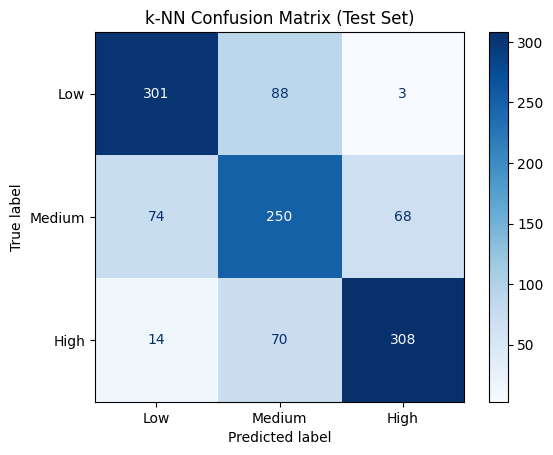

In [9]:
# TODO: Report and interpret the classification results.

print("Best parameters:", grid.best_params_)
print(f"Best CV macro F1: {grid.best_score_:.3f}")
print("PCA components kept:", best_knn.named_steps["pca"].n_components_)
print()
print(f"Test accuracy: {accuracy_score(y_test_labels, y_pred_labels):.3f}")
print(f"Test macro F1: {f1_score(y_test_labels, y_pred_labels, average='macro'):.3f}")
print()

segment_order = ["Low", "Medium", "High"]
print(classification_report(y_test_labels, y_pred_labels, labels=segment_order))

ConfusionMatrixDisplay.from_predictions(
    y_test_labels, y_pred_labels, labels=segment_order, cmap="Blues"
)
plt.title("k-NN Confusion Matrix (Test Set)")
plt.show()

### Classification results

The tuned pipeline uses **PCA keeping 90% of the variance (16 components)** and **k-NN with k = 21, Manhattan distance and distance weighting**. On the held-out test set it reaches **75.3% accuracy and a macro F1 of 0.756**. The cross-validated macro F1 was 0.746, so the model generalizes about as well as cross-validation predicted. A random guess between three balanced classes would score about 33%.

**Performance by class:**
- **High (F1 0.82)** and **Low (F1 0.78)** are the easiest to tell apart. Only 10 High customers were predicted Low, and only 4 Low customers were predicted High. Big, frequent, diverse buyers look very different from one-off small buyers.
- **Medium (F1 0.67)** is the weak spot. It sits between the other two, so its neighbors are a mix of High and Low customers. Most errors involve Medium: 72 High and 87 Low customers were predicted Medium.

These scores come **without any spend columns**, using only volume, frequency, recency, diversity and favorite-product traits. That is a realistic estimate of how well the business could flag customer value for a new customer whose spend isn't yet known. One caveat: `TotalUnits` is still a strong proxy for spend. It isn't how the target is defined, but it does a lot of the work.

## Step 3: Product recommendation system

Here you will recommend products that are similar to a selected product based on product-level features.

Use PCA to simplify the feature space before computing nearest neighbors.

In [10]:
# TODO: Create a list of numeric product features to use for recommendations.
# Include only modeling features that describe product behavior/performance.
# Do NOT include identifiers or text-only columns such as StockCode or Description.

product_features = [
    "AvgUnitPrice", "PriceStd",                       # price level and price variability
    "TotalUnitsSold", "TotalRevenue", "NumInvoices",  # sales volume
    "UniqueCustomers", "CountriesSoldTo",             # reach
    "AvgQuantityPerInvoice", "UnitsPerCustomer", "RevenuePerCustomer",  # basket behavior
    "CustomerPenetration", "InvoicePenetration",      # penetration-style metrics
]

# Example idea: price, revenue, units sold, customer reach, and penetration-style metrics.
product_model_df = product_df_dedup.reset_index(drop=True)
print("Products:", len(product_model_df), "| Missing values in features:",
      int(product_model_df[product_features].isna().sum().sum()))

Products: 4631 | Missing values in features: 0


In [11]:
# TODO: Scale the product features and reduce dimensionality with PCA.
# In the sample solution, 3 components worked well for a compact but useful representation.

# Handle any missing values, then log-transform: volume/revenue features are extremely skewed,
# and without this a few best-sellers would dominate every distance calculation.
X_product = product_model_df[product_features].fillna(product_model_df[product_features].median())
X_product = np.log1p(X_product)

scaler_product = StandardScaler()
X_product_scaled = scaler_product.fit_transform(X_product)

pca_product = PCA(n_components=3, random_state=42)
X_product_pca = pca_product.fit_transform(X_product_scaled)

# Print
print("Variance explained per component:", np.round(pca_product.explained_variance_ratio_, 3))
print(f"Total variance retained with 3 components: {pca_product.explained_variance_ratio_.sum():.1%}")

Variance explained per component: [0.537 0.196 0.145]
Total variance retained with 3 components: 87.8%


In [12]:
# TODO: Fit a nearest-neighbors model on the PCA-transformed product features.
# Then choose one product and retrieve its nearest neighbors.

# Define model and fit
nn_model = NearestNeighbors(n_neighbors=6, metric="euclidean")
nn_model.fit(X_product_pca)

display_cols = ["StockCode", "Description", "Category", "AvgUnitPrice",
                "TotalUnitsSold", "UniqueCustomers", "CountriesSoldTo"]

def recommend_similar(index, n=5):
    """Return the query product plus its n most similar products in PCA space."""
    distances, indices = nn_model.kneighbors(X_product_pca[[index]], n_neighbors=n + 1)
    result = product_model_df.loc[indices[0], display_cols].copy()
    result["Distance"] = distances[0].round(3)
    result["Role"] = ["Query"] + ["Recommendation"] * n
    return result.reset_index(drop=True)

# Change this index if you want to inspect a different product.
query_index = 0

# distances, indices = ...
distances, indices = nn_model.kneighbors(X_product_pca[[query_index]])

# Use the returned indices to display the query product and its recommended products.
display(recommend_similar(query_index))

# A second example: the store's best-known product
best_seller_index = product_model_df.index[product_model_df["StockCode"] == "85123A"][0]
display(recommend_similar(best_seller_index))

,StockCode,Description,Category,AvgUnitPrice,TotalUnitsSold,UniqueCustomers,CountriesSoldTo,Distance,Role
0,10002,INFLATABLE POLITICAL GLOBE,General Gifts,0.841388,8624,164,12,0.000,Query
1,23076,ICE CREAM SUNDAE LIP GLOSS,General Gifts,1.244940,7920,202,14,0.380,Recommendation
2,23078,ICE CREAM PEN LIP GLOSS,Stationery & Crafts,1.245070,6607,159,12,0.415,Recommendation
3,79000,MOROCCAN TEA GLASS,Kitchen & Dining,0.826916,11609,195,13,0.417,Recommendation
4,22791,T-LIGHT GLASS FLUTED ANTIQUE,Kitchen & Dining,1.232640,9153,226,7,0.507,Recommendation
5,22988,SOLDIERS EGG CUP,Kitchen & Dining,1.256519,9389,207,4,0.549,Recommendation


,StockCode,Description,Category,AvgUnitPrice,TotalUnitsSold,UniqueCustomers,CountriesSoldTo,Distance,Role
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,Home Decor,2.870366,93697,1490,22,0.000,Query
1,22423,REGENCY CAKESTAND 3 TIER,General Gifts,12.461071,24899,1314,30,3.513,Recommendation
2,85099B,JUMBO BAG RED RETROSPOT,Storage & Bags,1.959759,94983,978,21,3.886,Recommendation
3,84879,ASSORTED COLOUR BIRD ORNAMENT,Garden & Outdoor,1.676403,79913,1010,19,4.706,Recommendation
4,21212,PACK OF 72 RETROSPOT CAKE CASES,Storage & Bags,0.541172,91263,1115,24,5.069,Recommendation
5,20725,LUNCH BAG RED RETROSPOT,Storage & Bags,1.646019,38314,845,20,5.380,Recommendation


### Recommendation results

The 12 product features were log-transformed, scaled and reduced to **3 principal components, which keep 87.8% of the variance**. PC1 (54%) is overall popularity and volume. PC2 (20%) separates higher-priced items from items bought in bulk. PC3 (15%) captures spend per customer and price variability. Nearest neighbors are found in that 3-D space.

- **Inflatable Political Globe (index 0):** the recommendations are other cheap novelty items, such as the ice-cream lip glosses, a Moroccan tea glass and a soldiers egg cup. All of them cost about £0.80–£1.25, sold 6,600–11,600 units to roughly 160–230 customers, and reached 4–14 countries. They come from different categories but behave alike commercially. That makes them useful as "customers who buy this kind of item also browse…" suggestions, or for placing on the same promotion page.
- **White Hanging Heart T-Light Holder (best seller):** its neighbors are the store's other top sellers, including the Regency cakestand, the Jumbo Bag Red Retrospot and the bird ornaments, each with roughly 850–1,500 customers. The distances are much larger (3.5+) because there are only a few products with sales that high. This works best as a "bestsellers" carousel.

**How PCA affects similarity:** the 12 raw features overlap heavily. For example, revenue, units, invoices and customers all measure popularity. Without PCA, popularity would be counted several times and would swamp price and basket behavior. PCA combines the overlapping features into separate directions and filters out noise, so the distances reflect several kinds of similarity.

**Limitation:** the features describe how products *sell*, not what they *are*. Recommendations can be the same kind of product to a business, like the globe and the lip gloss, without looking alike to a shopper. Adding category, description text or co-purchase data would make them more like a shopper would expect.

## Step 4: Customer segmentation with clustering

You will cluster customers using behavioral features from the joined dataset.

The goal is to compare:
- **K-Means** for hard clustering
- **GMM** for probabilistic clustering

In [13]:
# TODO: Start from the joined dataset and remove extreme outliers.
# This helps prevent a very small number of unusual customers from dominating the clusters.

cluster_df = joined_df.copy()

# Drop customers above the 99th percentile on the main volume metrics (wholesale-scale buyers).
upper = cluster_df[["TotalUnits", "NumInvoices", "UniqueProducts"]].quantile(0.99)
mask = (
    (cluster_df["TotalUnits"] <= upper["TotalUnits"])
    & (cluster_df["NumInvoices"] <= upper["NumInvoices"])
    & (cluster_df["UniqueProducts"] <= upper["UniqueProducts"])
)

cluster_df = cluster_df[mask].copy()
print("Rows used for clustering:", cluster_df.shape[0], f"(removed {(~mask).sum()} extreme customers)")

Rows used for clustering: 5752 (removed 126 extreme customers)


In [14]:
# TODO: Build the clustering feature list.
# The share columns may vary depending on the prepared CSV version, so build them dynamically.

base_cluster_features = [
    "TotalUnits",
    "NumInvoices",
    "UniqueProducts",
    "CustomerTenureDays",
    "RecencyDays",
    "AvgUnitsPerInvoice",
    "PurchaseFrequency",
    "RecencyRatio",
    "DiversityRatio",
    "TopCategoryShare",
    "CategoryDiversity",
]

share_cols = [c for c in cluster_df.columns if c.startswith("Share_")]
cluster_features = [c for c in base_cluster_features if c in cluster_df.columns] + share_cols

# Print the final feature list after you create it.
print(f"{len(cluster_features)} clustering features:", cluster_features)

16 clustering features: ['TotalUnits', 'NumInvoices', 'UniqueProducts', 'CustomerTenureDays', 'RecencyDays', 'AvgUnitsPerInvoice', 'PurchaseFrequency', 'RecencyRatio', 'DiversityRatio', 'TopCategoryShare', 'CategoryDiversity', 'Share_StorageBags', 'Share_GeneralGifts', 'Share_HomeDecor', 'Share_KitchenDining', 'Share_StationeryCrafts']


In [15]:
# TODO: Apply light transformations to reduce skew in the highest-volume variables.
# Then scale the data and apply PCA.

for col in [
    "TotalUnits",
    "NumInvoices",
    "UniqueProducts",
    "CustomerTenureDays",
    "RecencyDays",
    "AvgUnitsPerInvoice",
]:
    if col in cluster_df.columns:
        cluster_df[col] = np.log1p(cluster_df[col])

# Median-impute any missing values (none in this version of the data, but keeps the code safe).
X_cluster = cluster_df[cluster_features].fillna(cluster_df[cluster_features].median())

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

pca_cluster = PCA(n_components=0.90, random_state=42)   # keep 90% of the variance
X_cluster_pca = pca_cluster.fit_transform(X_cluster_scaled)

# After fitting PCA, print the number of components and the variance retained.
print("PCA components:", pca_cluster.n_components_)
print(f"Variance retained: {pca_cluster.explained_variance_ratio_.sum():.1%}")

PCA components: 8
Variance retained: 90.4%


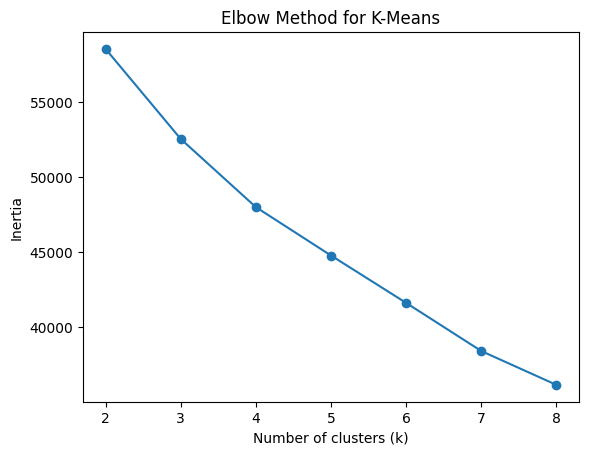

Drop in inertia from each extra cluster: [5996 4541 3223 3156 3207 2256]


In [16]:
# TODO: Use the elbow method to explore the best number of clusters for K-Means.

inertias = []
k_values = range(2, 9)

# Use a for loop to fit K-Means for each k and store the inertia.
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_pca)
    inertias.append(km.inertia_)

plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.show()

# Choose best_k based on the "elbow" point where the curve starts to level off.
print("Drop in inertia from each extra cluster:", np.round(-np.diff(inertias)).astype(int))

In [17]:
# TODO: Fit the final K-Means model using the k you selected from the elbow plot.
# Replace the value below after you inspect the plot.

# The biggest drops in inertia happen up to k=4; after that each extra cluster
# buys a roughly constant, smaller improvement, so k=4 is the elbow.
best_k = 4

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_df["KMeansCluster"] = kmeans.fit_predict(X_cluster_pca)

print(cluster_df["KMeansCluster"].value_counts().sort_index())

KMeansCluster
0    2174
1    1799
2    1226
3     553
Name: count, dtype: int64


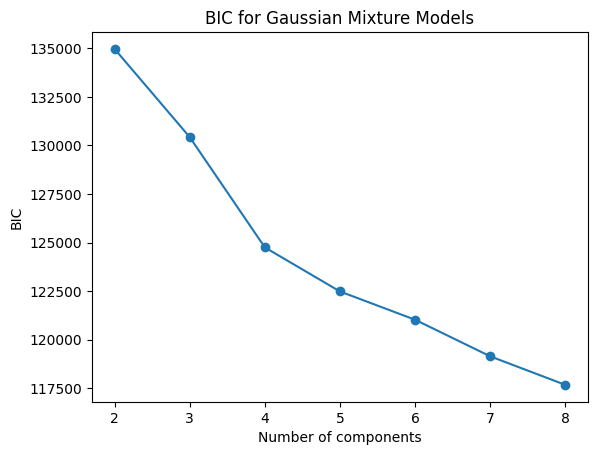

BIC by components: {2: np.int64(134968), 3: np.int64(130426), 4: np.int64(124748), 5: np.int64(122479), 6: np.int64(121024), 7: np.int64(119139), 8: np.int64(117670)}


In [18]:
# TODO: Use BIC to choose the number of components for GMM.

bic_scores = []
gmm_range = range(2, 9)

# Use a for loop to fit a GMM for each value and store the BIC score.
for n in gmm_range:
    gmm = GaussianMixture(n_components=n, covariance_type="full", random_state=42, n_init=3)
    gmm.fit(X_cluster_pca)
    bic_scores.append(gmm.bic(X_cluster_pca))

plt.plot(list(gmm_range), bic_scores, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC")
plt.title("BIC for Gaussian Mixture Models")
plt.show()

# Choose best_gmm_n as the number of components with the lowest BIC.
print("BIC by components:", dict(zip(gmm_range, np.round(bic_scores).astype(int))))

In [19]:
# TODO: Fit the final GMM model using the number of components with the lowest BIC.
# Replace the value below after you inspect the BIC plot.

best_gmm_n = list(gmm_range)[int(np.argmin(bic_scores))]
print("Components with the lowest BIC:", best_gmm_n)

gmm_final = GaussianMixture(n_components=best_gmm_n, covariance_type="full", random_state=42, n_init=3)
gmm_final.fit(X_cluster_pca)
cluster_df["GMMCluster"] = gmm_final.predict(X_cluster_pca)

# GMM is a soft method: keep each customer's highest membership probability as well
cluster_df["GMMMaxProb"] = gmm_final.predict_proba(X_cluster_pca).max(axis=1)

print(cluster_df["GMMCluster"].value_counts().sort_index())
print(f"Average max membership probability: {cluster_df['GMMMaxProb'].mean():.2f}")
print(f"Customers with max probability below 0.6 (uncertain membership): {(cluster_df['GMMMaxProb'] < 0.6).sum()}")

Components with the lowest BIC: 8
GMMCluster
0     614
1    1740
2     358
3     806
4    1499
5     274
6     184
7     277
Name: count, dtype: int64
Average max membership probability: 0.89
Customers with max probability below 0.6 (uncertain membership): 423


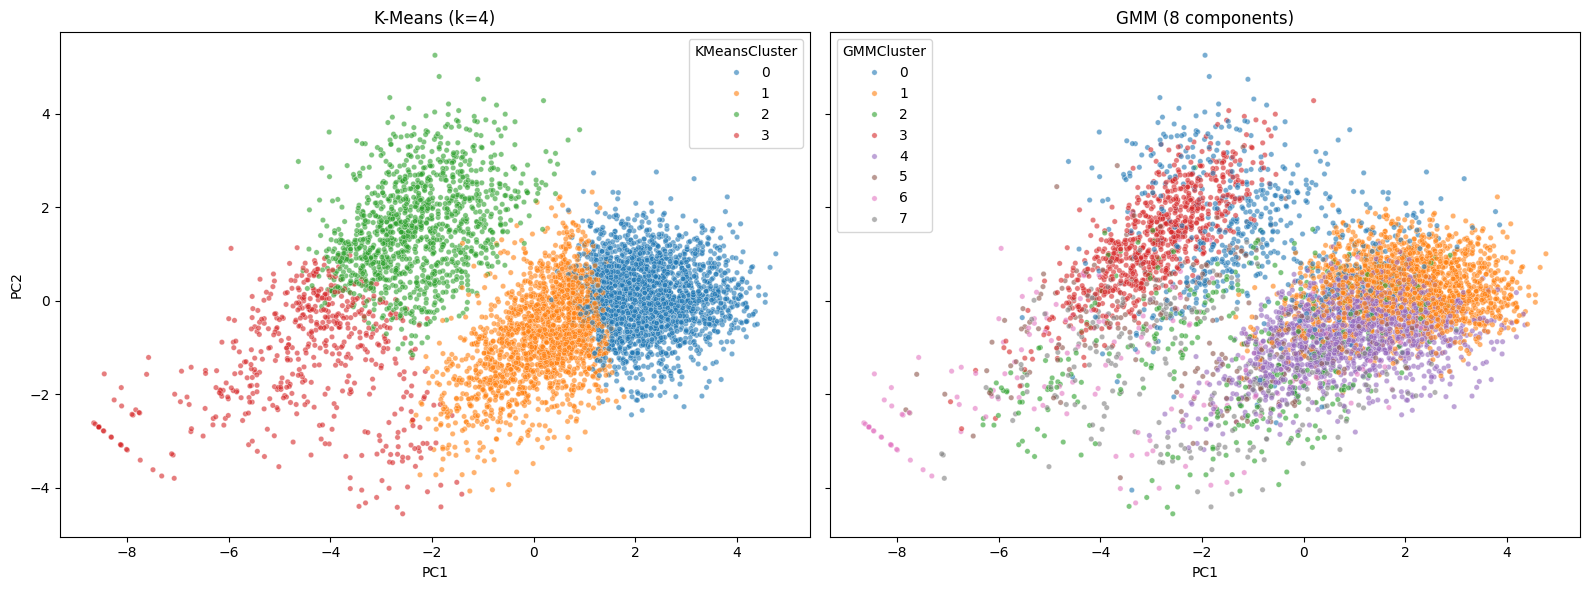

In [20]:
# TODO: Visualize the clusters using the first two principal components.

cluster_plot_df = pd.DataFrame({
    "PC1": X_cluster_pca[:, 0],
    "PC2": X_cluster_pca[:, 1],
    "KMeansCluster": cluster_df["KMeansCluster"].values,
    "GMMCluster": cluster_df["GMMCluster"].values,
})

# Build a plotting DataFrame that includes:
# - PC1
# - PC2
# - KMeansCluster
# - GMMCluster

# Then create side-by-side scatterplots to compare the two clustering methods.
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
sns.scatterplot(data=cluster_plot_df, x="PC1", y="PC2", hue="KMeansCluster",
                palette="tab10", s=15, alpha=0.6, ax=axes[0])
axes[0].set_title(f"K-Means (k={best_k})")
sns.scatterplot(data=cluster_plot_df, x="PC1", y="PC2", hue="GMMCluster",
                palette="tab10", s=15, alpha=0.6, ax=axes[1])
axes[1].set_title(f"GMM ({best_gmm_n} components)")
plt.tight_layout()
plt.show()

In [21]:
# Profile the segments using the original (un-logged) values so they are easy to read
profile_cols = ["TotalSpend", "NumInvoices", "TotalUnits", "UniqueProducts",
                "RecencyDays", "CustomerTenureDays", "CategoryDiversity"]
profile_source = joined_df.loc[cluster_df.index, profile_cols]

kmeans_profile = profile_source.groupby(cluster_df["KMeansCluster"]).median().round(1)
kmeans_profile.insert(0, "Customers", cluster_df["KMeansCluster"].value_counts().sort_index())
print("K-Means segment profiles (medians):")
display(kmeans_profile)

gmm_profile = profile_source.groupby(cluster_df["GMMCluster"]).median().round(1)
gmm_profile.insert(0, "Customers", cluster_df["GMMCluster"].value_counts().sort_index())
gmm_profile["AvgMaxProb"] = cluster_df.groupby("GMMCluster")["GMMMaxProb"].mean().round(2)
print("GMM segment profiles (medians):")
display(gmm_profile)

# How the two methods' groupings line up
print("K-Means clusters (rows) vs GMM clusters (columns):")
display(pd.crosstab(cluster_df["KMeansCluster"], cluster_df["GMMCluster"]))

K-Means segment profiles (medians):


,Customers,TotalSpend,NumInvoices,TotalUnits,UniqueProducts,RecencyDays,CustomerTenureDays,CategoryDiversity
KMeansCluster,,,,,,,,
0,2174,2634.4,7.0,1580.5,120.0,29.0,519.0,9.0
1,1799,731.2,3.0,371.0,34.0,189.0,240.0,7.0
2,1226,305.6,1.0,178.5,21.0,383.0,1.0,6.0
3,553,134.8,1.0,51.0,5.0,394.0,1.0,2.0


GMM segment profiles (medians):


,Customers,TotalSpend,NumInvoices,TotalUnits,UniqueProducts,RecencyDays,CustomerTenureDays,CategoryDiversity,AvgMaxProb
GMMCluster,,,,,,,,,
0,614,397.2,1.0,284.5,24.0,61.0,1.0,6.0,0.90
1,1740,2184.2,6.0,1362.5,101.0,46.0,452.0,9.0,0.89
2,358,436.1,2.0,228.0,24.0,64.5,24.0,6.0,0.87
3,806,251.1,1.0,134.0,19.0,448.5,1.0,6.0,0.96
4,1499,1160.4,4.0,590.0,58.0,89.0,372.0,8.0,0.85
5,274,364.8,2.0,191.0,13.0,156.5,21.0,4.0,0.91
6,184,357.3,1.0,89.0,5.0,267.0,1.0,2.0,0.96
7,277,339.6,2.0,190.0,11.0,185.0,29.0,4.0,0.92


K-Means clusters (rows) vs GMM clusters (columns):


GMMCluster,0,1,2,3,4,5,6,7
KMeansCluster,,,,,,,,
0,107,1359,60,0,607,12,15,14
1,114,381,144,0,884,123,39,114
2,375,0,73,680,0,49,12,37
3,18,0,81,126,8,90,118,112


### Comparing K-Means and GMM

**Model selection:**
- **K-Means:** inertia falls quickly up to **k = 4** (drops of about 6,000, 4,500 and 3,200). After that, each extra cluster saves roughly the same smaller amount, so k = 4 is the elbow.
- **GMM:** BIC keeps falling across the whole 2–8 range, so the lowest-BIC choice is **8 components**. As the lab notes, the two methods optimize different objectives. GMM's flexible full-covariance clusters can keep improving its likelihood by carving out smaller, tightly shaped groups.

**K-Means segments (k = 4, medians):**

| Cluster | Customers | Profile | Median spend |
|---|---|---|---|
| 0 | 2,174 | **Loyal high-value**: 7 invoices, bought 29 days ago, ~17-month tenure, all 9 categories | £2,634 |
| 1 | 1,799 | **Mid-value occasional**: 3 invoices, last purchase ~6 months ago | £731 |
| 2 | 1,226 | **Lapsed one-time buyers**: 1 invoice over a year ago | £306 |
| 3 | 553 | **Small one-off browsers**: 1 invoice, ~5 products from 2 categories, over a year ago | £135 |

**GMM segments (8 components):**
- **Same as K-Means:** GMM picks out the same main groups. Its cluster 1 matches loyal high-value, cluster 4 matches mid-value regulars, and cluster 3 matches lapsed one-time buyers.
- **New: recent first-time buyers.** Cluster 0 bought about 2 months ago.
- **New: category specialists.** These customers spend over 60% of their basket in one category: **Home Décor** (cluster 2), **Storage & Bags** (cluster 5), **Kitchen & Dining** (cluster 7) and **General Gifts** (cluster 6, 85% in one category).

K-Means mixes the specialists into its broader groups because it only looks at distance to a cluster center.

**Hard vs. soft assignment:**
- **Confidence:** the average GMM membership probability is 0.89, but **423 customers fall below 0.6**. These are borderline customers that K-Means forces into one group without flagging any uncertainty.
- **How the groupings line up:** the crosstab shows K-Means cluster 0 splitting mainly into GMM 1 and 4. K-Means clusters 2 and 3 split across the recent, lapsed and specialist GMM groups.

**About the scatter plots:** they show only 2 of the 8 principal components, so clusters that look overlapping there are separated in the dimensions not shown.

**Which is more useful?**
- **K-Means** gives four clear segments that are easy to act on and follow a value-and-engagement ladder: retain, grow, win back, ignore or cheap reactivation.
- **GMM** gives richer segments for **targeted category marketing** and **onboarding new buyers**. It also gives probabilities, so uncertain customers can be left out of costly campaigns.

A practical approach is to run lifecycle strategy on the K-Means segments and use the GMM specialist segments for category-specific promotions.

## Reflection questions

Answer these in markdown cells below the relevant sections.

1. Why was it important to remove variables like `TotalSpend` from the classification feature set?
2. How did PCA help in the classification, recommendation, and clustering tasks?
3. What differences do you notice between the K-Means and GMM clustering results?
4. Which customer or product insights seem the most actionable from a business perspective?

### Reflection answers

**1. Why was it important to remove variables like `TotalSpend` from the classification feature set?**
`ValueSegment` is created directly from `TotalSpend` with tertile cut-offs. If `TotalSpend` were a feature, the model would just learn those cut-offs and score close to 100%, which tells us nothing. `AvgOrderValue` (spend ÷ invoices) and `SpendPerProduct` (spend ÷ products) also contain spend, so they leak the target too. With them removed, the model has to predict value from behavior (frequency, volume, recency, diversity, product preferences). The resulting 75% accuracy is honest and would carry over to customers whose spend is not yet known.

**2. How did PCA help in the classification, recommendation, and clustering tasks?**
- **Classification:** after one-hot encoding there were dozens of overlapping features. PCA kept 90% of the variance in 16 components, which cuts noise and duplicate information. That matters for k-NN, whose distances get less meaningful as dimensions grow. Because PCA sits inside the pipeline, it is fit only on the training folds, so it adds no leakage. The amount of variance kept was tuned as a hyperparameter.
- **Recommendation:** 3 components kept 88% of the product variance. They combined the many overlapping popularity metrics into one direction, so similarity also reflects price and basket behavior. The 3-D space is also fast to search.
- **Clustering:** 8 components kept 90% of the variance from 16 features. That gives K-Means and GMM a smaller, decorrelated space to work in, which is especially important for full-covariance GMM. It also provided PC1 and PC2 for the scatter plots.

**3. What differences do you notice between the K-Means and GMM clustering results?**
- **Number of clusters:** K-Means' elbow suggested 4, while GMM's BIC kept improving up to 8.
- **Shape of the segments:** K-Means produced a simple value-and-recency ladder. GMM found the same main groups and also separated recent first-time buyers and four single-category specialist groups (Home Décor, Storage & Bags, Kitchen & Dining, General Gifts).
- **Hard vs. soft:** K-Means gives every customer exactly one label. GMM gives probabilities and flagged 423 customers whose membership is uncertain (max probability below 0.6).
- **Ease of use:** K-Means segments are easier to explain. GMM segments are more detailed and support targeting by category.

**4. Which customer or product insights seem the most actionable from a business perspective?**
- **Protect the loyal high-value segment.** About 2,200 customers (K-Means 0) buy often, bought recently and buy across every category, and they hold most of the High-value customers. They are the best fit for loyalty perks, early access and account management.
- **Win back the lapsed one-time buyers.** About 1,800 customers (K-Means 2 and 3) bought once over a year ago. A low-cost reactivation email is worth testing. The smallest browsers may not be worth paid campaigns.
- **Turn recent first-time buyers into repeat buyers.** This GMM segment bought recently but only once, so a well-timed second-purchase offer could move them up the value ladder.
- **Run category-specific campaigns for the GMM specialists.** For example, send new Home Décor items to the Home Décor group, and cross-sell related categories to grow their baskets.
- **Use the product recommender** for "similar items" and bestseller carousels.
- **Use the k-NN classifier** to score new customers' likely value early, before much spend history exists, so marketing budget goes to the most promising ones.

**Limitations and next steps:**
- Some favorite codes are not real products (postage, test items) and should be removed before production use.
- The recommender uses how products sell, not what they are. Adding category or text features would help.
- Segments should be checked against a future time period, for example with an A/B test of the targeted campaigns, before rollout.